In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

# Reproducibility
np.random.seed(42)

# Project directory
PROJECT_ROOT = Path.cwd().parent

# Reporting period
REPORTING_MONTH = "2026-11"
CURRENCY = "EUR"

print("Company: Northstar Global Services Ltd.")
print("Reporting period:", REPORTING_MONTH)
print("Currency:", CURRENCY)
print("Project directory:", PROJECT_ROOT)

Company: Northstar Global Services Ltd.
Reporting period: 2026-11
Currency: EUR
Project directory: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics


In [2]:
# ==========================================
# NORTHSTAR GLOBAL SERVICES LTD.
# CHART OF ACCOUNTS
# ==========================================

accounts = [
    # ASSETS
    ["1000", "Bank Account", "Asset", "Debit", "Balance Sheet"],
    ["1100", "Accounts Receivable", "Asset", "Debit", "Balance Sheet"],
    ["1200", "Prepaid Expenses", "Asset", "Debit", "Balance Sheet"],
    ["1500", "Equipment", "Asset", "Debit", "Balance Sheet"],
    ["1590", "Accumulated Depreciation", "Asset", "Credit", "Balance Sheet"],

    # LIABILITIES
    ["2000", "Accounts Payable", "Liability", "Credit", "Balance Sheet"],
    ["2100", "Accrued Expenses", "Liability", "Credit", "Balance Sheet"],
    ["2200", "Bank Loan", "Liability", "Credit", "Balance Sheet"],

    # EQUITY
    ["3000", "Share Capital", "Equity", "Credit", "Balance Sheet"],
    ["3100", "Retained Earnings", "Equity", "Credit", "Balance Sheet"],

    # REVENUE
    ["4000", "Service Revenue", "Revenue", "Credit", "Profit and Loss"],
    ["4100", "Interest Income", "Revenue", "Credit", "Profit and Loss"],

    # EXPENSES
    ["5000", "Salaries Expense", "Expense", "Debit", "Profit and Loss"],
    ["5100", "Rent Expense", "Expense", "Debit", "Profit and Loss"],
    ["5200", "Utilities Expense", "Expense", "Debit", "Profit and Loss"],
    ["5300", "Software Expense", "Expense", "Debit", "Profit and Loss"],
    ["5400", "Travel Expense", "Expense", "Debit", "Profit and Loss"],
    ["5500", "Depreciation Expense", "Expense", "Debit", "Profit and Loss"],
    ["5600", "Bank Charges", "Expense", "Debit", "Profit and Loss"],
    ["5700", "Interest Expense", "Expense", "Debit", "Profit and Loss"]
]

columns = [
    "account_code",
    "account_name",
    "account_type",
    "normal_balance",
    "financial_statement"
]

chart_of_accounts = pd.DataFrame(accounts, columns=columns)

# Save the Chart of Accounts
output_path = PROJECT_ROOT / "data" / "raw" / "chart_of_accounts.csv"

chart_of_accounts.to_csv(output_path, index=False)

# Display the results
print("Chart of Accounts successfully created!")
print("Number of accounts:", len(chart_of_accounts))
print("Saved to:", output_path)

display(chart_of_accounts)

Chart of Accounts successfully created!
Number of accounts: 20
Saved to: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\raw\chart_of_accounts.csv


,account_code,account_name,account_type,normal_balance,financial_statement
0,1000,Bank Account,Asset,Debit,Balance Sheet
1,1100,Accounts Receivable,Asset,Debit,Balance Sheet
2,1200,Prepaid Expenses,Asset,Debit,Balance Sheet
3,1500,Equipment,Asset,Debit,Balance Sheet
4,1590,Accumulated Depreciation,Asset,Credit,Balance Sheet
5,2000,Accounts Payable,Liability,Credit,Balance Sheet
6,2100,Accrued Expenses,Liability,Credit,Balance Sheet
7,2200,Bank Loan,Liability,Credit,Balance Sheet
8,3000,Share Capital,Equity,Credit,Balance Sheet
9,3100,Retained Earnings,Equity,Credit,Balance Sheet


In [3]:
# Check for duplicate account codes
duplicate_codes = chart_of_accounts[
    chart_of_accounts["account_code"].duplicated()
]

# Check for missing values
missing_values = chart_of_accounts.isnull().sum()

# Account distribution
account_summary = (
    chart_of_accounts
    .groupby("account_type")
    .size()
    .reset_index(name="number_of_accounts")
)

print("Duplicate account codes:", len(duplicate_codes))
print("\nMissing values:")
print(missing_values)
print("\nAccounts by category:")
display(account_summary)

Duplicate account codes: 0

Missing values:
account_code           0
account_name           0
account_type           0
normal_balance         0
financial_statement    0
dtype: int64

Accounts by category:


,account_type,number_of_accounts
0,Asset,5
1,Equity,2
2,Expense,8
3,Liability,3
4,Revenue,2


In [4]:

# ============================================================
# NORTHSTAR GLOBAL SERVICES LTD.
# NOVEMBER 2026 - SYNTHETIC FINANCIAL DATA GENERATOR
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

rng = np.random.default_rng(42)

# Project configuration
PERIOD_START = pd.Timestamp("2026-11-01")
PERIOD_END = pd.Timestamp("2026-11-30")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. MASTER DATA
# ------------------------------------------------------------

customers = [
    "Alpine Consulting",
    "BluePeak Technologies",
    "Central European Logistics",
    "Delta Business Solutions",
    "Evergreen Retail Group",
    "FutureWorks Ltd."
]

suppliers = [
    "OfficePro Supplies",
    "CloudTech Services",
    "City Properties",
    "Utility Partners",
    "Travel Solutions"
]

departments = ["Operations", "IT", "Finance", "Sales", "HR"]

# ------------------------------------------------------------
# 2. STORAGE FOR GENERATED RECORDS
# ------------------------------------------------------------

journal_rows = []
bank_rows = []
ar_rows = []
ap_rows = []

transaction_counter = 1
bank_counter = 1

def next_transaction_id():
    global transaction_counter
    transaction_id = f"TXN{transaction_counter:05d}"
    transaction_counter += 1
    return transaction_id

def add_journal(transaction_id, date, description,
                debit_account, credit_account, amount,
                department="Operations"):

    amount = round(float(amount), 2)

    if amount <= 0:
        raise ValueError("Transaction amount must be positive.")

    common = {
        "transaction_id": transaction_id,
        "date": pd.Timestamp(date),
        "description": description,
        "department": department
    }

    journal_rows.append({
        **common,
        "account_code": debit_account,
        "debit": amount,
        "credit": 0.00
    })

    journal_rows.append({
        **common,
        "account_code": credit_account,
        "debit": 0.00,
        "credit": amount
    })

def add_bank_record(date, description, transaction_id,
                    amount, direction):

    global bank_counter

    signed_amount = (
        amount if direction == "Credit"
        else -amount
    )

    bank_rows.append({
        "bank_transaction_id": f"BANK{bank_counter:05d}",
        "transaction_id": transaction_id,
        "date": pd.Timestamp(date),
        "description": description,
        "credit": amount if direction == "Credit" else 0.00,
        "debit": amount if direction == "Debit" else 0.00,
        "signed_amount": signed_amount
    })

    bank_counter += 1

# ------------------------------------------------------------
# 3. CUSTOMER INVOICES AND COLLECTIONS
# ------------------------------------------------------------

for i in range(12):

    date = PERIOD_START + pd.Timedelta(
        days=int(rng.integers(0, 24))
    )

    amount = round(float(rng.uniform(3000, 12000)), 2)
    customer = rng.choice(customers)
    department = "Sales"

    txn = next_transaction_id()

    # Invoice: Debit Receivables, Credit Revenue
    add_journal(
        txn, date, f"Customer invoice - {customer}",
        "1100", "4000", amount, department
    )

    ar_rows.append({
        "invoice_id": f"AR{i+1:04d}",
        "transaction_id": txn,
        "customer": customer,
        "invoice_date": date,
        "due_date": date + pd.Timedelta(days=30),
        "invoice_amount": amount,
        "status": "Outstanding"
    })

# Collect payment on selected customer invoices
for i in range(8):

    invoice = ar_rows[i]
    amount = invoice["invoice_amount"]

    date = invoice["invoice_date"] + pd.Timedelta(
        days=int(rng.integers(1, 8))
    )

    txn = next_transaction_id()

    # Debit Bank, Credit Receivables
    add_journal(
        txn, date, f"Customer payment - {invoice['customer']}",
        "1000", "1100", amount, "Sales"
    )

    add_bank_record(
        date, f"Customer payment - {invoice['customer']}",
        txn, amount, "Credit"
    )

    ar_rows[i]["status"] = "Paid"

# ------------------------------------------------------------
# 4. SUPPLIER INVOICES AND PAYMENTS
# ------------------------------------------------------------

expense_accounts = [
    ("5000", "Salaries Expense"),
    ("5100", "Rent Expense"),
    ("5200", "Utilities Expense"),
    ("5300", "Software Expense"),
    ("5400", "Travel Expense")
]

for i in range(12):

    date = PERIOD_START + pd.Timedelta(
        days=int(rng.integers(0, 24))
    )

    supplier = rng.choice(suppliers)
    account_code, expense_name = expense_accounts[
        int(rng.integers(0, len(expense_accounts)))
    ]

    amount = round(float(rng.uniform(500, 6000)), 2)
    txn = next_transaction_id()

    # Supplier invoice: Debit Expense, Credit Payables
    add_journal(
        txn, date, f"Supplier invoice - {supplier}",
        account_code, "2000", amount, "Operations"
    )

    ap_rows.append({
        "invoice_id": f"AP{i+1:04d}",
        "transaction_id": txn,
        "supplier": supplier,
        "invoice_date": date,
        "due_date": date + pd.Timedelta(days=30),
        "expense_account": account_code,
        "invoice_amount": amount,
        "status": "Outstanding"
    })

# Pay selected supplier invoices
for i in range(8):

    invoice = ap_rows[i]
    amount = invoice["invoice_amount"]

    date = invoice["invoice_date"] + pd.Timedelta(
        days=int(rng.integers(1, 8))
    )

    txn = next_transaction_id()

    # Debit Payables, Credit Bank
    add_journal(
        txn, date, f"Supplier payment - {invoice['supplier']}",
        "2000", "1000", amount, "Operations"
    )

    add_bank_record(
        date, f"Supplier payment - {invoice['supplier']}",
        txn, amount, "Debit"
    )

    ap_rows[i]["status"] = "Paid"

# ------------------------------------------------------------
# 5. OTHER OPERATING EXPENSES PAID THROUGH THE BANK
# ------------------------------------------------------------

other_expenses = [
    ("5000", "Monthly salaries", 18000, 24000),
    ("5100", "Office rent", 3000, 4500),
    ("5200", "Utilities", 600, 1200),
    ("5300", "Software subscriptions", 500, 1500),
    ("5400", "Business travel", 700, 1800),
    ("5600", "Bank charges", 100, 300)
]

for account, description, minimum, maximum in other_expenses:

    amount = round(float(rng.uniform(minimum, maximum)), 2)

    date = PERIOD_START + pd.Timedelta(
        days=int(rng.integers(0, 28))
    )

    txn = next_transaction_id()

    add_journal(
        txn, date, description,
        account, "1000", amount, "Finance"
    )

    add_bank_record(
        date, description, txn, amount, "Debit"
    )

# ------------------------------------------------------------
# 6. EQUIPMENT PURCHASE
# ------------------------------------------------------------

equipment_amount = 8500.00
equipment_date = pd.Timestamp("2026-11-12")
txn = next_transaction_id()

add_journal(
    txn, equipment_date, "Purchase of office equipment",
    "1500", "1000", equipment_amount, "Operations"
)

add_bank_record(
    equipment_date, "Purchase of office equipment",
    txn, equipment_amount, "Debit"
)

# ------------------------------------------------------------
# 7. DEPRECIATION
# ------------------------------------------------------------

depreciation_amount = 250.00
txn = next_transaction_id()

add_journal(
    txn, pd.Timestamp("2026-11-30"), "Monthly depreciation",
    "5500", "1590", depreciation_amount, "Finance"
)

# Depreciation is a non-cash expense, so no bank transaction.

# ------------------------------------------------------------
# 8. LOAN RECEIVED
# ------------------------------------------------------------

loan_amount = 20000.00
loan_date = pd.Timestamp("2026-11-05")
txn = next_transaction_id()

add_journal(
    txn, loan_date, "Bank loan received",
    "1000", "2200", loan_amount, "Finance"
)

add_bank_record(
    loan_date, "Bank loan received",
    txn, loan_amount, "Credit"
)

# ------------------------------------------------------------
# 9. INTEREST INCOME RECEIVED
# ------------------------------------------------------------

interest_income = 150.00
interest_date = pd.Timestamp("2026-11-25")
txn = next_transaction_id()

add_journal(
    txn, interest_date, "Interest income received",
    "1000", "4100", interest_income, "Finance"
)

add_bank_record(
    interest_date, "Interest income received",
    txn, interest_income, "Credit"
)

# ------------------------------------------------------------
# 10. CREATE DATAFRAMES
# ------------------------------------------------------------

general_ledger = pd.DataFrame(journal_rows)
bank_statement = pd.DataFrame(bank_rows)
accounts_receivable = pd.DataFrame(ar_rows)
accounts_payable = pd.DataFrame(ap_rows)

# ------------------------------------------------------------
# 11. INTRODUCE CONTROLLED BANK EXCEPTIONS
# ------------------------------------------------------------

# Remove one bank transaction to simulate a missing bank record.
missing_record = bank_statement.iloc[[2]].copy()
bank_statement = bank_statement.drop(bank_statement.index[2])

# Introduce a duplicate bank transaction.
duplicate_record = bank_statement.iloc[[4]].copy()
duplicate_record["bank_transaction_id"] = (
    f"BANK{bank_counter:05d}"
)
duplicate_record["description"] += " - DUPLICATE"
bank_counter += 1

bank_statement = pd.concat(
    [bank_statement, duplicate_record],
    ignore_index=True
)

# Introduce a bank-side fee not yet recorded in the GL.
bank_statement.loc[len(bank_statement)] = {
    "bank_transaction_id": f"BANK{bank_counter:05d}",
    "transaction_id": "BANKFEE001",
    "date": pd.Timestamp("2026-11-28"),
    "description": "Unrecorded bank service fee",
    "credit": 0.00,
    "debit": 45.00,
    "signed_amount": -45.00
}

# ------------------------------------------------------------
# 12. GENERATE BUDGET
# ------------------------------------------------------------

budget_data = [
    ["Revenue", "Service Revenue", 4000, 105000],
    ["Revenue", "Interest Income", 4100, 200],
    ["Expense", "Salaries Expense", 5000, 22000],
    ["Expense", "Rent Expense", 5100, 4000],
    ["Expense", "Utilities Expense", 5200, 1000],
    ["Expense", "Software Expense", 5300, 1200],
    ["Expense", "Travel Expense", 5400, 1500],
    ["Expense", "Depreciation Expense", 5500, 250],
    ["Expense", "Bank Charges", 5600, 200],
    ["Expense", "Interest Expense", 5700, 500]
]

budget = pd.DataFrame(
    budget_data,
    columns=[
        "category",
        "account_name",
        "account_code",
        "budget_amount"
    ]
)

budget["period"] = "2026-11"

# ------------------------------------------------------------
# 13. SAVE DATASETS
# ------------------------------------------------------------

datasets = {
    "general_ledger.csv": general_ledger,
    "bank_statement.csv": bank_statement,
    "accounts_receivable.csv": accounts_receivable,
    "accounts_payable.csv": accounts_payable,
    "budget.csv": budget
}

for filename, dataframe in datasets.items():
    dataframe.to_csv(RAW_DIR / filename, index=False)

print("FINANCIAL DATA GENERATION COMPLETED")
print("-" * 55)

for filename, dataframe in datasets.items():
    print(f"{filename}: {len(dataframe):,} rows")

print("\nAll datasets saved in:", RAW_DIR)


FINANCIAL DATA GENERATION COMPLETED
-------------------------------------------------------
general_ledger.csv: 100 rows
bank_statement.csv: 26 rows
accounts_receivable.csv: 12 rows
accounts_payable.csv: 12 rows
budget.csv: 10 rows

All datasets saved in: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\raw


In [5]:
# Preview the generated datasets

print("GENERAL LEDGER")
display(general_ledger.head(10))

print("BANK STATEMENT")
display(bank_statement.head(10))

print("ACCOUNTS RECEIVABLE")
display(accounts_receivable.head())

print("ACCOUNTS PAYABLE")
display(accounts_payable.head())

print("BUDGET")
display(budget)

GENERAL LEDGER


,transaction_id,date,description,department,account_code,debit,credit
0,TXN00001,2026-11-03,Customer invoice - Evergreen Retail Group,Sales,1100,6949.91,0.00
1,TXN00001,2026-11-03,Customer invoice - Evergreen Retail Group,Sales,4000,0.00,6949.91
2,TXN00002,2026-11-11,Customer invoice - FutureWorks Ltd.,Sales,1100,9276.31,0.00
3,TXN00002,2026-11-11,Customer invoice - FutureWorks Ltd.,Sales,4000,0.00,9276.31
4,TXN00003,2026-11-05,Customer invoice - Alpine Consulting,Sales,1100,11780.60,0.00
5,TXN00003,2026-11-05,Customer invoice - Alpine Consulting,Sales,4000,0.00,11780.60
6,TXN00004,2026-11-18,Customer invoice - Evergreen Retail Group,Sales,1100,10074.58,0.00
7,TXN00004,2026-11-18,Customer invoice - Evergreen Retail Group,Sales,4000,0.00,10074.58
8,TXN00005,2026-11-13,Customer invoice - Alpine Consulting,Sales,1100,7053.47,0.00
9,TXN00005,2026-11-13,Customer invoice - Alpine Consulting,Sales,4000,0.00,7053.47


BANK STATEMENT


,bank_transaction_id,transaction_id,date,description,credit,debit,signed_amount
0,BANK00001,TXN00013,2026-11-08,Customer payment - Evergreen Retail Group,6949.91,0.00,6949.91
1,BANK00002,TXN00014,2026-11-17,Customer payment - FutureWorks Ltd.,9276.31,0.00,9276.31
2,BANK00004,TXN00016,2026-11-20,Customer payment - Evergreen Retail Group,10074.58,0.00,10074.58
3,BANK00005,TXN00017,2026-11-16,Customer payment - Alpine Consulting,7053.47,0.00,7053.47
4,BANK00006,TXN00018,2026-11-17,Customer payment - Central European Logistics,11340.88,0.00,11340.88
5,BANK00007,TXN00019,2026-11-23,Customer payment - Delta Business Solutions,10404.85,0.00,10404.85
6,BANK00008,TXN00020,2026-11-15,Customer payment - Central European Logistics,5045.15,0.00,5045.15
7,BANK00009,TXN00033,2026-11-15,Supplier payment - OfficePro Supplies,0.00,4596.19,-4596.19
8,BANK00010,TXN00034,2026-11-18,Supplier payment - CloudTech Services,0.00,2292.04,-2292.04
9,BANK00011,TXN00035,2026-11-24,Supplier payment - CloudTech Services,0.00,1542.09,-1542.09


ACCOUNTS RECEIVABLE


,invoice_id,transaction_id,customer,invoice_date,due_date,invoice_amount,status
0,AR0001,TXN00001,Evergreen Retail Group,2026-11-03,2026-12-03,6949.91,Paid
1,AR0002,TXN00002,FutureWorks Ltd.,2026-11-11,2026-12-11,9276.31,Paid
2,AR0003,TXN00003,Alpine Consulting,2026-11-05,2026-12-05,11780.60,Paid
3,AR0004,TXN00004,Evergreen Retail Group,2026-11-18,2026-12-18,10074.58,Paid
4,AR0005,TXN00005,Alpine Consulting,2026-11-13,2026-12-13,7053.47,Paid


ACCOUNTS PAYABLE


,invoice_id,transaction_id,supplier,invoice_date,due_date,expense_account,invoice_amount,status
0,AP0001,TXN00021,OfficePro Supplies,2026-11-14,2026-12-14,5300,4596.19,Paid
1,AP0002,TXN00022,CloudTech Services,2026-11-17,2026-12-17,5400,2292.04,Paid
2,AP0003,TXN00023,CloudTech Services,2026-11-22,2026-12-22,5000,1542.09,Paid
3,AP0004,TXN00024,City Properties,2026-11-12,2026-12-12,5000,3116.38,Paid
4,AP0005,TXN00025,CloudTech Services,2026-11-08,2026-12-08,5200,2904.34,Paid


BUDGET


,category,account_name,account_code,budget_amount,period
0,Revenue,Service Revenue,4000,105000,2026-11
1,Revenue,Interest Income,4100,200,2026-11
2,Expense,Salaries Expense,5000,22000,2026-11
3,Expense,Rent Expense,5100,4000,2026-11
4,Expense,Utilities Expense,5200,1000,2026-11
5,Expense,Software Expense,5300,1200,2026-11
6,Expense,Travel Expense,5400,1500,2026-11
7,Expense,Depreciation Expense,5500,250,2026-11
8,Expense,Bank Charges,5600,200,2026-11
9,Expense,Interest Expense,5700,500,2026-11


In [6]:

# ============================================================
# GENERAL LEDGER VALIDATION
# ============================================================

# Load the Chart of Accounts from the saved CSV
chart_of_accounts = pd.read_csv(
    RAW_DIR / "chart_of_accounts.csv",
    dtype={"account_code": str}
)

# Ensure account codes have the same data type
general_ledger["account_code"] = (
    general_ledger["account_code"].astype(str)
)

# ------------------------------------------------------------
# CHECK 1: DEBITS MUST EQUAL CREDITS PER TRANSACTION
# ------------------------------------------------------------

journal_balance = (
    general_ledger
    .groupby("transaction_id")
    .agg(
        total_debit=("debit", "sum"),
        total_credit=("credit", "sum"),
        number_of_lines=("transaction_id", "size")
    )
    .reset_index()
)

journal_balance["difference"] = (
    journal_balance["total_debit"]
    - journal_balance["total_credit"]
).round(2)

unbalanced_journals = journal_balance[
    journal_balance["difference"] != 0
]

# ------------------------------------------------------------
# CHECK 2: EACH TRANSACTION HAS DEBIT AND CREDIT LINES
# ------------------------------------------------------------

journal_sides = (
    general_ledger
    .groupby("transaction_id")
    .agg(
        debit_lines=("debit", lambda x: (x > 0).sum()),
        credit_lines=("credit", lambda x: (x > 0).sum())
    )
    .reset_index()
)

invalid_journals = journal_sides[
    (journal_sides["debit_lines"] == 0) |
    (journal_sides["credit_lines"] == 0)
]

# ------------------------------------------------------------
# CHECK 3: ALL ACCOUNT CODES MUST EXIST
# ------------------------------------------------------------

valid_account_codes = set(
    chart_of_accounts["account_code"].astype(str)
)

invalid_account_records = general_ledger[
    ~general_ledger["account_code"].isin(valid_account_codes)
]

# ------------------------------------------------------------
# CHECK 4: TRANSACTION DATES
# ------------------------------------------------------------

general_ledger["date"] = pd.to_datetime(
    general_ledger["date"]
)

invalid_dates = general_ledger[
    (general_ledger["date"] < PERIOD_START) |
    (general_ledger["date"] > PERIOD_END)
]

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("GENERAL LEDGER VALIDATION REPORT")
print("=" * 50)

print("Total ledger lines:", len(general_ledger))
print("Unique journal entries:", general_ledger["transaction_id"].nunique())

print("\n1. Journal balancing")
print("Unbalanced journal entries:", len(unbalanced_journals))

print("\n2. Debit and credit line validation")
print("Invalid journal entries:", len(invalid_journals))

print("\n3. Account code validation")
print("Invalid account records:", len(invalid_account_records))

print("\n4. Reporting period validation")
print("Transactions outside November:", len(invalid_dates))

print("\nOVERALL RESULT")

if (
    len(unbalanced_journals) == 0
    and len(invalid_journals) == 0
    and len(invalid_account_records) == 0
    and len(invalid_dates) == 0
):
    print("PASS: All General Ledger validation checks passed.")
else:
    print("FAIL: One or more validation checks require investigation.")


GENERAL LEDGER VALIDATION REPORT
Total ledger lines: 100
Unique journal entries: 50

1. Journal balancing
Unbalanced journal entries: 0

2. Debit and credit line validation
Invalid journal entries: 0

3. Account code validation
Invalid account records: 0

4. Reporting period validation
Transactions outside November: 0

OVERALL RESULT
PASS: All General Ledger validation checks passed.


In [7]:
# ============================================================
# EXTRACT BANK ACCOUNT TRANSACTIONS FROM GENERAL LEDGER
# ============================================================

gl_bank = general_ledger[
    general_ledger["account_code"] == "1000"
].copy()

gl_bank["gl_amount"] = (
    gl_bank["debit"] - gl_bank["credit"]
).round(2)

gl_bank = gl_bank[
    [
        "transaction_id",
        "date",
        "description",
        "gl_amount"
    ]
].copy()

print("GENERAL LEDGER BANK TRANSACTIONS")
print("Number of transactions:", len(gl_bank))

display(gl_bank.head(10))

GENERAL LEDGER BANK TRANSACTIONS
Number of transactions: 25


,transaction_id,date,description,gl_amount
24,TXN00013,2026-11-08,Customer payment - Evergreen Retail Group,6949.91
26,TXN00014,2026-11-17,Customer payment - FutureWorks Ltd.,9276.31
28,TXN00015,2026-11-11,Customer payment - Alpine Consulting,11780.60
30,TXN00016,2026-11-20,Customer payment - Evergreen Retail Group,10074.58
32,TXN00017,2026-11-16,Customer payment - Alpine Consulting,7053.47
34,TXN00018,2026-11-17,Customer payment - Central European Logistics,11340.88
36,TXN00019,2026-11-23,Customer payment - Delta Business Solutions,10404.85
38,TXN00020,2026-11-15,Customer payment - Central European Logistics,5045.15
65,TXN00033,2026-11-15,Supplier payment - OfficePro Supplies,-4596.19
67,TXN00034,2026-11-18,Supplier payment - CloudTech Services,-2292.04


In [8]:
# ============================================================
# PREPARE BANK STATEMENT
# ============================================================

bank_recon = bank_statement.copy()

bank_recon["bank_amount"] = (
    bank_recon["credit"] - bank_recon["debit"]
).round(2)

print("BANK STATEMENT TRANSACTIONS")
print("Number of transactions:", len(bank_recon))

display(
    bank_recon[
        [
            "bank_transaction_id",
            "transaction_id",
            "date",
            "description",
            "bank_amount"
        ]
    ].head(10)
)

BANK STATEMENT TRANSACTIONS
Number of transactions: 26


,bank_transaction_id,transaction_id,date,description,bank_amount
0,BANK00001,TXN00013,2026-11-08,Customer payment - Evergreen Retail Group,6949.91
1,BANK00002,TXN00014,2026-11-17,Customer payment - FutureWorks Ltd.,9276.31
2,BANK00004,TXN00016,2026-11-20,Customer payment - Evergreen Retail Group,10074.58
3,BANK00005,TXN00017,2026-11-16,Customer payment - Alpine Consulting,7053.47
4,BANK00006,TXN00018,2026-11-17,Customer payment - Central European Logistics,11340.88
5,BANK00007,TXN00019,2026-11-23,Customer payment - Delta Business Solutions,10404.85
6,BANK00008,TXN00020,2026-11-15,Customer payment - Central European Logistics,5045.15
7,BANK00009,TXN00033,2026-11-15,Supplier payment - OfficePro Supplies,-4596.19
8,BANK00010,TXN00034,2026-11-18,Supplier payment - CloudTech Services,-2292.04
9,BANK00011,TXN00035,2026-11-24,Supplier payment - CloudTech Services,-1542.09


In [9]:
# ============================================================
# IDENTIFY DUPLICATE BANK TRANSACTIONS
# ============================================================

duplicate_mask = bank_recon.duplicated(
    subset=["transaction_id"],
    keep="first"
)

duplicate_bank_transactions = bank_recon[
    duplicate_mask
].copy()

# Keep one record per transaction for the initial matching
bank_unique = bank_recon.drop_duplicates(
    subset=["transaction_id"],
    keep="first"
).copy()

print("DUPLICATE TRANSACTION REPORT")
print("Duplicate records detected:", len(duplicate_bank_transactions))

display(duplicate_bank_transactions)

DUPLICATE TRANSACTION REPORT
Duplicate records detected: 1


,bank_transaction_id,transaction_id,date,description,credit,debit,signed_amount,bank_amount
24,BANK00026,TXN00018,2026-11-17,Customer payment - Central European Logistics ...,11340.88,0.0,11340.88,11340.88


In [10]:
# ============================================================
# AUTOMATED BANK RECONCILIATION ENGINE
# ============================================================

reconciliation = gl_bank.merge(
    bank_unique[
        [
            "transaction_id",
            "bank_transaction_id",
            "date",
            "bank_amount"
        ]
    ],
    on="transaction_id",
    how="outer",
    suffixes=("_gl", "_bank"),
    indicator=True
)

# Determine reconciliation status
def classify_transaction(row):

    if row["_merge"] == "left_only":
        return "Missing from Bank Statement"

    elif row["_merge"] == "right_only":
        return "Not Recorded in General Ledger"

    elif not np.isclose(
        row["gl_amount"],
        row["bank_amount"],
        atol=0.01
    ):
        return "Amount Mismatch"

    else:
        return "Matched"

reconciliation["reconciliation_status"] = (
    reconciliation.apply(classify_transaction, axis=1)
)

# Identify duplicate transactions separately
duplicate_ids = set(
    duplicate_bank_transactions["transaction_id"]
)

reconciliation["duplicate_flag"] = (
    reconciliation["transaction_id"].isin(duplicate_ids)
)

# Save the reconciliation output
reconciliation_path = (
    PROJECT_ROOT / "data" / "processed" /
    "bank_reconciliation.csv"
)

reconciliation_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

reconciliation.to_csv(
    reconciliation_path,
    index=False
)

print("BANK RECONCILIATION COMPLETED")
print("Total reconciliation records:", len(reconciliation))

display(
    reconciliation[
        [
            "transaction_id",
            "gl_amount",
            "bank_amount",
            "reconciliation_status",
            "duplicate_flag"
        ]
    ]
)

BANK RECONCILIATION COMPLETED
Total reconciliation records: 26


,transaction_id,gl_amount,bank_amount,reconciliation_status,duplicate_flag
0,BANKFEE001,NaN,-45.00,Not Recorded in General Ledger,False
1,TXN00013,6949.91,6949.91,Matched,False
2,TXN00014,9276.31,9276.31,Matched,False
3,TXN00015,11780.60,NaN,Missing from Bank Statement,False
4,TXN00016,10074.58,10074.58,Matched,False
5,TXN00017,7053.47,7053.47,Matched,False
6,TXN00018,11340.88,11340.88,Matched,True
7,TXN00019,10404.85,10404.85,Matched,False
8,TXN00020,5045.15,5045.15,Matched,False
9,TXN00033,-4596.19,-4596.19,Matched,False


In [11]:
# ============================================================
# BANK RECONCILIATION EXCEPTION REPORT
# ============================================================

reconciliation_summary = (
    reconciliation
    .groupby("reconciliation_status")
    .size()
    .reset_index(name="number_of_transactions")
)

print("BANK RECONCILIATION SUMMARY")
print("=" * 50)

display(reconciliation_summary)

print("\nDUPLICATE BANK TRANSACTIONS")
display(
    duplicate_bank_transactions[
        [
            "bank_transaction_id",
            "transaction_id",
            "description",
            "bank_amount"
        ]
    ]
)

print("\nRECONCILIATION EXCEPTIONS")
exceptions = reconciliation[
    reconciliation["reconciliation_status"] != "Matched"
]

display(
    exceptions[
        [
            "transaction_id",
            "description",
            "gl_amount",
            "bank_amount",
            "reconciliation_status",
            "duplicate_flag"
        ]
    ]
)

print("\nReconciliation saved to:", reconciliation_path)

BANK RECONCILIATION SUMMARY


,reconciliation_status,number_of_transactions
0,Matched,24
1,Missing from Bank Statement,1
2,Not Recorded in General Ledger,1



DUPLICATE BANK TRANSACTIONS


,bank_transaction_id,transaction_id,description,bank_amount
24,BANK00026,TXN00018,Customer payment - Central European Logistics ...,11340.88



RECONCILIATION EXCEPTIONS


,transaction_id,description,gl_amount,bank_amount,reconciliation_status,duplicate_flag
0,BANKFEE001,NaN,NaN,-45.0,Not Recorded in General Ledger,False
3,TXN00015,Customer payment - Alpine Consulting,11780.6,NaN,Missing from Bank Statement,False



Reconciliation saved to: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\processed\bank_reconciliation.csv


In [12]:
# Consolidated exceptions:
# Include unmatched transactions AND matched transactions with duplicates

all_exceptions = reconciliation[
    (reconciliation["reconciliation_status"] != "Matched") |
    (reconciliation["duplicate_flag"] == True)
].copy()

print("CONSOLIDATED BANK RECONCILIATION EXCEPTIONS")
print("=" * 65)

display(
    all_exceptions[
        [
            "transaction_id",
            "gl_amount",
            "bank_amount",
            "reconciliation_status",
            "duplicate_flag"
        ]
    ]
)

print("\nTotal exceptions:", len(all_exceptions))

CONSOLIDATED BANK RECONCILIATION EXCEPTIONS


,transaction_id,gl_amount,bank_amount,reconciliation_status,duplicate_flag
0,BANKFEE001,NaN,-45.00,Not Recorded in General Ledger,False
3,TXN00015,11780.60,NaN,Missing from Bank Statement,False
6,TXN00018,11340.88,11340.88,Matched,True



Total exceptions: 3


In [13]:
# Record the unposted bank service fee

bank_fee_entry = pd.DataFrame([
    {
        "transaction_id": "BANKFEE001",
        "date": "2026-11-28",
        "description": "Record bank service fee",
        "account_code": "5600",
        "debit": 45.00,
        "credit": 0.00
    },
    {
        "transaction_id": "BANKFEE001",
        "date": "2026-11-28",
        "description": "Record bank service fee",
        "account_code": "1000",
        "debit": 0.00,
        "credit": 45.00
    }
])

general_ledger = pd.concat(
    [general_ledger, bank_fee_entry],
    ignore_index=True
)

print("Bank fee journal entry added.")
display(bank_fee_entry)

# Check that the journal balances
print(
    "Total debit:",
    general_ledger[
        general_ledger["transaction_id"] == "BANKFEE001"
    ]["debit"].sum()
)

print(
    "Total credit:",
    general_ledger[
        general_ledger["transaction_id"] == "BANKFEE001"
    ]["credit"].sum()
)

Bank fee journal entry added.


,transaction_id,date,description,account_code,debit,credit
0,BANKFEE001,2026-11-28,Record bank service fee,5600,45.0,0.0
1,BANKFEE001,2026-11-28,Record bank service fee,1000,0.0,45.0


Total debit: 45.0
Total credit: 45.0


In [14]:
# Revalidate the updated General Ledger

general_ledger["account_code"] = (
    general_ledger["account_code"].astype(str)
)

journal_check = (
    general_ledger.groupby("transaction_id")
    .agg(
        total_debit=("debit", "sum"),
        total_credit=("credit", "sum"),
        line_count=("transaction_id", "count")
    )
    .reset_index()
)

journal_check["difference"] = (
    journal_check["total_debit"] -
    journal_check["total_credit"]
).round(2)

unbalanced = journal_check[
    journal_check["difference"].abs() > 0.01
]

invalid_accounts = general_ledger[
    ~general_ledger["account_code"].isin(
        chart_of_accounts["account_code"].astype(str)
    )
]

print("UPDATED GENERAL LEDGER VALIDATION")
print("=" * 50)
print("Total ledger lines:", len(general_ledger))
print("Unique journal entries:", general_ledger["transaction_id"].nunique())
print("Unbalanced journals:", len(unbalanced))
print("Invalid account records:", len(invalid_accounts))

print("\nBank fee journal:")
display(
    journal_check[
        journal_check["transaction_id"] == "BANKFEE001"
    ]
)

if len(unbalanced) == 0 and len(invalid_accounts) == 0:
    print("\nPASS: Updated General Ledger validation successful.")
else:
    print("\nWARNING: Review the validation exceptions.")

UPDATED GENERAL LEDGER VALIDATION
Total ledger lines: 102
Unique journal entries: 51
Unbalanced journals: 0
Invalid account records: 0

Bank fee journal:


,transaction_id,total_debit,total_credit,line_count,difference
0,BANKFEE001,45.0,45.0,2,0.0



PASS: Updated General Ledger validation successful.


In [15]:
gl_path = (
    PROJECT_ROOT / "data" / "raw" / "general_ledger.csv"
)

general_ledger.to_csv(gl_path, index=False)

print("Updated General Ledger saved to:", gl_path)

Updated General Ledger saved to: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\raw\general_ledger.csv


In [16]:
# ==========================================
# UPDATED BANK RECONCILIATION
# ==========================================

# 1. Extract bank transactions from the General Ledger
gl_bank = general_ledger[
    general_ledger["account_code"] == "1000"
].copy()

gl_bank["gl_amount"] = (
    gl_bank["debit"] - gl_bank["credit"]
).round(2)

gl_bank = gl_bank[
    ["transaction_id", "description", "gl_amount"]
]

# 2. Calculate signed bank statement movements
bank_recon = bank_statement.copy()

bank_recon["bank_amount"] = (
    bank_recon["credit"] - bank_recon["debit"]
).round(2)

# 3. Detect duplicate bank transaction IDs
duplicate_mask = bank_recon.duplicated(
    subset=["transaction_id"],
    keep="first"
)

duplicate_bank_transactions = bank_recon[
    duplicate_mask
].copy()

duplicate_ids = set(
    duplicate_bank_transactions["transaction_id"]
)

# Keep one record per transaction ID for matching
bank_unique = bank_recon.drop_duplicates(
    subset=["transaction_id"],
    keep="first"
).copy()

# 4. Match the General Ledger against the bank statement
reconciliation = gl_bank.merge(
    bank_unique[
        ["transaction_id", "bank_transaction_id", "bank_amount"]
    ],
    on="transaction_id",
    how="outer",
    indicator=True
)

# 5. Classify reconciliation results
def classify_transaction(row):
    if row["_merge"] == "left_only":
        return "Missing from Bank Statement"

    elif row["_merge"] == "right_only":
        return "Not Recorded in General Ledger"

    elif not np.isclose(
        row["gl_amount"],
        row["bank_amount"],
        atol=0.01
    ):
        return "Amount Mismatch"

    return "Matched"


reconciliation["reconciliation_status"] = (
    reconciliation.apply(classify_transaction, axis=1)
)

# 6. Flag duplicate transactions
reconciliation["duplicate_flag"] = (
    reconciliation["transaction_id"].isin(duplicate_ids)
)

# 7. Save updated reconciliation
reconciliation_path = (
    PROJECT_ROOT / "data" / "processed" / "bank_reconciliation.csv"
)

reconciliation_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

reconciliation.to_csv(
    reconciliation_path,
    index=False
)

# 8. Display reconciliation summary
reconciliation_summary = (
    reconciliation.groupby("reconciliation_status")
    .size()
    .reset_index(name="number_of_transactions")
)

print("UPDATED BANK RECONCILIATION REPORT")
print("=" * 60)

display(reconciliation_summary)

print("\nDUPLICATE TRANSACTIONS")
display(
    duplicate_bank_transactions[
        ["bank_transaction_id", "transaction_id", "description", "bank_amount"]
    ]
)

print("\nALL RECONCILIATION EXCEPTIONS")

all_exceptions = reconciliation[
    (reconciliation["reconciliation_status"] != "Matched") |
    (reconciliation["duplicate_flag"])
]

display(
    all_exceptions[
        [
            "transaction_id",
            "gl_amount",
            "bank_amount",
            "reconciliation_status",
            "duplicate_flag"
        ]
    ]
)

print("\nTotal reconciliation records:", len(reconciliation))
print("Total exceptions:", len(all_exceptions))
print("Saved to:", reconciliation_path)

UPDATED BANK RECONCILIATION REPORT


,reconciliation_status,number_of_transactions
0,Matched,25
1,Missing from Bank Statement,1



DUPLICATE TRANSACTIONS


,bank_transaction_id,transaction_id,description,bank_amount
24,BANK00026,TXN00018,Customer payment - Central European Logistics ...,11340.88



ALL RECONCILIATION EXCEPTIONS


,transaction_id,gl_amount,bank_amount,reconciliation_status,duplicate_flag
3,TXN00015,11780.60,NaN,Missing from Bank Statement,False
6,TXN00018,11340.88,11340.88,Matched,True



Total reconciliation records: 26
Total exceptions: 2
Saved to: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\processed\bank_reconciliation.csv


In [17]:
# ==========================================
# RECORD OPENING BALANCES
# ==========================================

opening_entry = pd.DataFrame([
    {
        "transaction_id": "OPENING001",
        "date": "2026-11-01",
        "description": "Opening bank balance",
        "account_code": "1000",
        "debit": 50000.00,
        "credit": 0.00
    },
    {
        "transaction_id": "OPENING001",
        "date": "2026-11-01",
        "description": "Opening share capital",
        "account_code": "3000",
        "debit": 0.00,
        "credit": 50000.00
    }
])

# Prevent accidental duplicate insertion if the cell is rerun
if "OPENING001" not in general_ledger["transaction_id"].values:
    general_ledger = pd.concat(
        [general_ledger, opening_entry],
        ignore_index=True
    )

print("OPENING JOURNAL ENTRY")
display(opening_entry)

print("Opening journal debit:",
      opening_entry["debit"].sum())

print("Opening journal credit:",
      opening_entry["credit"].sum())

OPENING JOURNAL ENTRY


,transaction_id,date,description,account_code,debit,credit
0,OPENING001,2026-11-01,Opening bank balance,1000,50000.0,0.0
1,OPENING001,2026-11-01,Opening share capital,3000,0.0,50000.0


Opening journal debit: 50000.0
Opening journal credit: 50000.0


In [18]:
gl_path = PROJECT_ROOT / "data" / "raw" / "general_ledger.csv"

general_ledger.to_csv(gl_path, index=False)

print("Updated General Ledger saved:", gl_path)
print("Total ledger lines:", len(general_ledger))
print("Unique journal entries:", general_ledger["transaction_id"].nunique())

Updated General Ledger saved: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\raw\general_ledger.csv
Total ledger lines: 104
Unique journal entries: 52


In [19]:
# ==========================================
# NOVEMBER 2026 PROFIT & LOSS STATEMENT
# ==========================================

# Aggregate debit and credit movements by account
pl_data = (
    general_ledger.groupby("account_code")
    .agg(
        total_debit=("debit", "sum"),
        total_credit=("credit", "sum")
    )
    .reset_index()
)

# Attach account names and account types
pl_data = pl_data.merge(
    chart_of_accounts[
        ["account_code", "account_name", "account_type"]
    ],
    on="account_code",
    how="left"
)

# Keep revenue and expense accounts only
pl_data = pl_data[
    pl_data["account_type"].isin(["Revenue", "Expenses"])
].copy()

# Calculate positive revenue and expense balances
pl_data["actual_amount"] = np.where(
    pl_data["account_type"] == "Revenue",
    pl_data["total_credit"] - pl_data["total_debit"],
    pl_data["total_debit"] - pl_data["total_credit"]
).round(2)

# Organise the report
pl_statement = pl_data[
    ["account_code", "account_name", "account_type", "actual_amount"]
].sort_values(
    ["account_type", "account_code"]
).reset_index(drop=True)

# Calculate totals
total_revenue = pl_statement.loc[
    pl_statement["account_type"] == "Revenue",
    "actual_amount"
].sum()

total_expenses = pl_statement.loc[
    pl_statement["account_type"] == "Expenses",
    "actual_amount"
].sum()

net_profit = round(total_revenue - total_expenses, 2)

# Display the report
print("NORTHSTAR GLOBAL SERVICES LTD.")
print("PROFIT & LOSS STATEMENT")
print("For the month ended 30 November 2026")
print("=" * 60)

print("\nREVENUE")
display(
    pl_statement[
        pl_statement["account_type"] == "Revenue"
    ][["account_code", "account_name", "actual_amount"]]
)

print("Total Revenue: €{:,.2f}".format(total_revenue))

print("\nEXPENSES")
display(
    pl_statement[
        pl_statement["account_type"] == "Expenses"
    ][["account_code", "account_name", "actual_amount"]]
)

print("Total Expenses: €{:,.2f}".format(total_expenses))

print("\nNET PROFIT / (LOSS): €{:,.2f}".format(net_profit))

NORTHSTAR GLOBAL SERVICES LTD.
PROFIT & LOSS STATEMENT
For the month ended 30 November 2026

REVENUE


,account_code,account_name,actual_amount
0,4000,Service Revenue,101413.91
1,4100,Interest Income,150.00


Total Revenue: €101,563.91

EXPENSES


,account_code,account_name,actual_amount


Total Expenses: €0.00

NET PROFIT / (LOSS): €101,563.91


In [20]:
pl_path = (
    PROJECT_ROOT / "data" / "processed" / "profit_and_loss.csv"
)

pl_path.parent.mkdir(parents=True, exist_ok=True)

pl_statement.to_csv(pl_path, index=False)

print("Profit & Loss report saved to:", pl_path)

Profit & Loss report saved to: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\processed\profit_and_loss.csv


In [21]:
# Inspect account classifications in the Chart of Accounts

print("ACCOUNT TYPES IN CHART OF ACCOUNTS")
print(chart_of_accounts["account_type"].value_counts())

print("\nALL ACCOUNT CODES AND CLASSIFICATIONS")
display(
    chart_of_accounts[
        ["account_code", "account_name", "account_type"]
    ].sort_values("account_code")
)

ACCOUNT TYPES IN CHART OF ACCOUNTS
account_type
Expense      8
Asset        5
Liability    3
Equity       2
Revenue      2
Name: count, dtype: int64

ALL ACCOUNT CODES AND CLASSIFICATIONS


,account_code,account_name,account_type
0,1000,Bank Account,Asset
1,1100,Accounts Receivable,Asset
2,1200,Prepaid Expenses,Asset
3,1500,Equipment,Asset
4,1590,Accumulated Depreciation,Asset
5,2000,Accounts Payable,Liability
6,2100,Accrued Expenses,Liability
7,2200,Bank Loan,Liability
8,3000,Share Capital,Equity
9,3100,Retained Earnings,Equity


In [22]:
# Inspect expense account movements in the General Ledger

expense_accounts = chart_of_accounts[
    chart_of_accounts["account_type"].str.lower().str.contains("expense")
]

expense_check = general_ledger[
    general_ledger["account_code"].isin(
        expense_accounts["account_code"].astype(str)
    )
]

print("Expense accounts identified:", len(expense_accounts))
print("General Ledger expense lines:", len(expense_check))

display(expense_check.head(15))

Expense accounts identified: 8
General Ledger expense lines: 20


,transaction_id,date,description,department,account_code,debit,credit
40,TXN00021,2026-11-14 00:00:00,Supplier invoice - OfficePro Supplies,Operations,5300,4596.19,0.0
42,TXN00022,2026-11-17 00:00:00,Supplier invoice - CloudTech Services,Operations,5400,2292.04,0.0
44,TXN00023,2026-11-22 00:00:00,Supplier invoice - CloudTech Services,Operations,5000,1542.09,0.0
46,TXN00024,2026-11-12 00:00:00,Supplier invoice - City Properties,Operations,5000,3116.38,0.0
48,TXN00025,2026-11-08 00:00:00,Supplier invoice - CloudTech Services,Operations,5200,2904.34,0.0
50,TXN00026,2026-11-17 00:00:00,Supplier invoice - OfficePro Supplies,Operations,5400,4351.46,0.0
52,TXN00027,2026-11-03 00:00:00,Supplier invoice - CloudTech Services,Operations,5300,4926.20,0.0
54,TXN00028,2026-11-20 00:00:00,Supplier invoice - Travel Solutions,Operations,5100,2085.80,0.0
56,TXN00029,2026-11-06 00:00:00,Supplier invoice - Utility Partners,Operations,5300,1599.50,0.0
58,TXN00030,2026-11-04 00:00:00,Supplier invoice - Travel Solutions,Operations,5000,4828.08,0.0


In [23]:
# ==========================================
# CORRECTED NOVEMBER 2026 PROFIT & LOSS
# ==========================================

pl_data = (
    general_ledger.groupby("account_code")
    .agg(
        total_debit=("debit", "sum"),
        total_credit=("credit", "sum")
    )
    .reset_index()
)

pl_data = pl_data.merge(
    chart_of_accounts[
        ["account_code", "account_name", "account_type"]
    ],
    on="account_code",
    how="left"
)

# Correct classification: Revenue and Expense
pl_data = pl_data[
    pl_data["account_type"].isin(["Revenue", "Expense"])
].copy()

# Calculate account balances
pl_data["actual_amount"] = np.where(
    pl_data["account_type"] == "Revenue",
    pl_data["total_credit"] - pl_data["total_debit"],
    pl_data["total_debit"] - pl_data["total_credit"]
).round(2)

pl_statement = pl_data[
    ["account_code", "account_name", "account_type", "actual_amount"]
].sort_values(
    ["account_type", "account_code"]
).reset_index(drop=True)

# Calculate totals
total_revenue = pl_statement.loc[
    pl_statement["account_type"] == "Revenue",
    "actual_amount"
].sum()

total_expenses = pl_statement.loc[
    pl_statement["account_type"] == "Expense",
    "actual_amount"
].sum()

net_profit = round(total_revenue - total_expenses, 2)

# Display statement
print("NORTHSTAR GLOBAL SERVICES LTD.")
print("PROFIT & LOSS STATEMENT")
print("For the month ended 30 November 2026")
print("=" * 60)

print("\nREVENUE")
display(
    pl_statement[
        pl_statement["account_type"] == "Revenue"
    ][["account_code", "account_name", "actual_amount"]]
)

print("Total Revenue: €{:,.2f}".format(total_revenue))

print("\nEXPENSES")
display(
    pl_statement[
        pl_statement["account_type"] == "Expense"
    ][["account_code", "account_name", "actual_amount"]]
)

print("Total Expenses: €{:,.2f}".format(total_expenses))

print("\nNET PROFIT: €{:,.2f}".format(net_profit))

NORTHSTAR GLOBAL SERVICES LTD.
PROFIT & LOSS STATEMENT
For the month ended 30 November 2026

REVENUE


,account_code,account_name,actual_amount
7,4000,Service Revenue,101413.91
8,4100,Interest Income,150.00


Total Revenue: €101,563.91

EXPENSES


,account_code,account_name,actual_amount
0,5000,Salaries Expense,30877.97
1,5100,Rent Expense,6037.88
2,5200,Utilities Expense,12258.58
3,5300,Software Expense,11925.84
4,5400,Travel Expense,7377.40
5,5500,Depreciation Expense,250.00
6,5600,Bank Charges,187.92


Total Expenses: €68,915.59

NET PROFIT: €32,648.32


In [24]:
pl_path = (
    PROJECT_ROOT / "data" / "processed" / "profit_and_loss.csv"
)

pl_statement.to_csv(pl_path, index=False)

print("Corrected Profit & Loss saved to:", pl_path)

Corrected Profit & Loss saved to: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\processed\profit_and_loss.csv


In [25]:
# ==========================================
# NOVEMBER 2026 BALANCE SHEET PREPARATION
# ==========================================

# Aggregate all ledger movements
account_balances = (
    general_ledger.groupby("account_code")
    .agg(
        total_debit=("debit", "sum"),
        total_credit=("credit", "sum")
    )
    .reset_index()
)

# Attach Chart of Accounts information
account_balances = account_balances.merge(
    chart_of_accounts[
        [
            "account_code",
            "account_name",
            "account_type",
            "normal_balance"
        ]
    ],
    on="account_code",
    how="left"
)

# Calculate balances according to normal balance
account_balances["closing_balance"] = np.where(
    account_balances["normal_balance"].str.lower() == "debit",
    account_balances["total_debit"] - account_balances["total_credit"],
    account_balances["total_credit"] - account_balances["total_debit"]
).round(2)

print("ACCOUNT CLOSING BALANCES")
print("=" * 60)

display(
    account_balances[
        [
            "account_code",
            "account_name",
            "account_type",
            "normal_balance",
            "closing_balance"
        ]
    ].sort_values("account_code")
)

ACCOUNT CLOSING BALANCES


,account_code,account_name,account_type,normal_balance,closing_balance
0,1000,Bank Account,Asset,Debit,79759.83
1,1100,Accounts Receivable,Asset,Debit,29488.16
2,1500,Equipment,Asset,Debit,8500.00
3,1590,Accumulated Depreciation,Asset,Credit,250.00
4,2000,Accounts Payable,Liability,Credit,14849.67
5,2200,Bank Loan,Liability,Credit,20000.00
6,3000,Share Capital,Equity,Credit,50000.00
7,4000,Service Revenue,Revenue,Credit,101413.91
8,4100,Interest Income,Revenue,Credit,150.00
9,5000,Salaries Expense,Expense,Debit,30877.97


In [28]:
# ==========================================
# CORRECTED BALANCE SHEET
# ==========================================

assets = account_balances[
    account_balances["account_type"] == "Asset"
].copy()

liabilities = account_balances[
    account_balances["account_type"] == "Liability"
].copy()

equity = account_balances[
    account_balances["account_type"] == "Equity"
].copy()

# Present normal debit-balance assets as positive
# and credit-balance contra-assets as negative
assets["presentation_balance"] = np.where(
    assets["normal_balance"].str.lower() == "debit",
    assets["closing_balance"],
    -assets["closing_balance"]
)

total_assets = assets["presentation_balance"].sum()

total_liabilities = liabilities["closing_balance"].sum()

total_equity_before_profit = equity["closing_balance"].sum()

total_equity = total_equity_before_profit + net_profit

total_liabilities_equity = (
    total_liabilities + total_equity
)

balance_sheet_difference = round(
    total_assets - total_liabilities_equity, 2
)

# Display
print("NORTHSTAR GLOBAL SERVICES LTD.")
print("BALANCE SHEET")
print("As at 30 November 2026")
print("=" * 60)

print("\nASSETS")
display(
    assets[
        [
            "account_code",
            "account_name",
            "presentation_balance"
        ]
    ]
)

print("Total Assets: €{:,.2f}".format(total_assets))

print("\nLIABILITIES")
display(
    liabilities[
        ["account_code", "account_name", "closing_balance"]
    ]
)

print("Total Liabilities: €{:,.2f}".format(total_liabilities))

print("\nEQUITY")
display(
    equity[
        ["account_code", "account_name", "closing_balance"]
    ]
)

print("Current Period Net Profit: €{:,.2f}".format(net_profit))
print("Total Equity: €{:,.2f}".format(total_equity))

print("\nTOTAL LIABILITIES + EQUITY: €{:,.2f}".format(
    total_liabilities_equity
))

print("BALANCE SHEET DIFFERENCE: €{:,.2f}".format(
    balance_sheet_difference
))

if abs(balance_sheet_difference) <= 0.01:
    print("\nPASS: Balance Sheet balances.")
else:
    print("\nWARNING: Balance Sheet does not balance.")

NORTHSTAR GLOBAL SERVICES LTD.
BALANCE SHEET
As at 30 November 2026

ASSETS


,account_code,account_name,presentation_balance
0,1000,Bank Account,79759.83
1,1100,Accounts Receivable,29488.16
2,1500,Equipment,8500.00
3,1590,Accumulated Depreciation,-250.00


Total Assets: €117,497.99

LIABILITIES


,account_code,account_name,closing_balance
4,2000,Accounts Payable,14849.67
5,2200,Bank Loan,20000.00


Total Liabilities: €34,849.67

EQUITY


,account_code,account_name,closing_balance
6,3000,Share Capital,50000.0


Current Period Net Profit: €32,648.32
Total Equity: €82,648.32

TOTAL LIABILITIES + EQUITY: €117,497.99
BALANCE SHEET DIFFERENCE: €0.00

PASS: Balance Sheet balances.


In [29]:
# Create a clean Balance Sheet report
balance_sheet_report = pd.concat([
    assets.assign(statement_section="Assets"),
    liabilities.assign(
        presentation_balance=liabilities["closing_balance"],
        statement_section="Liabilities"
    ),
    equity.assign(
        presentation_balance=equity["closing_balance"],
        statement_section="Equity"
    )
], ignore_index=True)

balance_sheet_path = (
    PROJECT_ROOT / "data" / "processed" / "balance_sheet.csv"
)

balance_sheet_report.to_csv(
    balance_sheet_path,
    index=False
)

print("Corrected Balance Sheet saved to:", balance_sheet_path)

Corrected Balance Sheet saved to: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\processed\balance_sheet.csv


In [30]:
# ==========================================
# BUDGET VS ACTUAL: PREPARE ACTUALS
# ==========================================

# Aggregate November revenue and expense balances
actuals = (
    general_ledger.groupby("account_code")
    .agg(
        total_debit=("debit", "sum"),
        total_credit=("credit", "sum")
    )
    .reset_index()
)

actuals = actuals.merge(
    chart_of_accounts[
        ["account_code", "account_name", "account_type"]
    ],
    on="account_code",
    how="left"
)

actuals = actuals[
    actuals["account_type"].isin(["Revenue", "Expense"])
].copy()

actuals["actual_amount"] = np.where(
    actuals["account_type"] == "Revenue",
    actuals["total_credit"] - actuals["total_debit"],
    actuals["total_debit"] - actuals["total_credit"]
).round(2)

actuals = actuals[
    ["account_code", "account_name", "account_type", "actual_amount"]
]

print("NOVEMBER ACTUAL FINANCIAL PERFORMANCE")
display(actuals.sort_values("account_code"))

NOVEMBER ACTUAL FINANCIAL PERFORMANCE


,account_code,account_name,account_type,actual_amount
7,4000,Service Revenue,Revenue,101413.91
8,4100,Interest Income,Revenue,150.00
9,5000,Salaries Expense,Expense,30877.97
10,5100,Rent Expense,Expense,6037.88
11,5200,Utilities Expense,Expense,12258.58
12,5300,Software Expense,Expense,11925.84
13,5400,Travel Expense,Expense,7377.40
14,5500,Depreciation Expense,Expense,250.00
15,5600,Bank Charges,Expense,187.92


In [31]:
# ==========================================
# INSPECT NOVEMBER 2026 BUDGET
# ==========================================

budget = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "budget.csv"
)

print("BUDGET DATA")
print("=" * 60)

print("Number of budget records:", len(budget))
print("Budget columns:", budget.columns.tolist())

display(budget)

BUDGET DATA
Number of budget records: 10
Budget columns: ['category', 'account_name', 'account_code', 'budget_amount', 'period']


,category,account_name,account_code,budget_amount,period
0,Revenue,Service Revenue,4000,105000,2026-11
1,Revenue,Interest Income,4100,200,2026-11
2,Expense,Salaries Expense,5000,22000,2026-11
3,Expense,Rent Expense,5100,4000,2026-11
4,Expense,Utilities Expense,5200,1000,2026-11
5,Expense,Software Expense,5300,1200,2026-11
6,Expense,Travel Expense,5400,1500,2026-11
7,Expense,Depreciation Expense,5500,250,2026-11
8,Expense,Bank Charges,5600,200,2026-11
9,Expense,Interest Expense,5700,500,2026-11


In [32]:
# ==========================================
# BUDGET VS ACTUAL ANALYSIS
# ==========================================

# Ensure account codes have the same data type
budget["account_code"] = budget["account_code"].astype(str)
actuals["account_code"] = actuals["account_code"].astype(str)

# Merge budget with actual financial performance
budget_vs_actual = budget.merge(
    actuals[
        ["account_code", "actual_amount"]
    ],
    on="account_code",
    how="left"
)

# Accounts without a General Ledger posting have zero actuals
budget_vs_actual["actual_amount"] = (
    budget_vs_actual["actual_amount"].fillna(0)
)

# Calculate variance using the appropriate convention
budget_vs_actual["variance"] = np.where(
    budget_vs_actual["category"] == "Revenue",
    budget_vs_actual["actual_amount"] - budget_vs_actual["budget_amount"],
    budget_vs_actual["budget_amount"] - budget_vs_actual["actual_amount"]
)

# Calculate variance percentage
budget_vs_actual["variance_percentage"] = np.where(
    budget_vs_actual["budget_amount"] != 0,
    (budget_vs_actual["variance"] / budget_vs_actual["budget_amount"]) * 100,
    np.nan
)

# Classify performance
budget_vs_actual["performance"] = np.select(
    [
        budget_vs_actual["variance"] > 0,
        budget_vs_actual["variance"] < 0
    ],
    [
        "Favourable",
        "Unfavourable"
    ],
    default="On Budget"
)

# Round financial figures
budget_vs_actual["actual_amount"] = budget_vs_actual["actual_amount"].round(2)
budget_vs_actual["variance"] = budget_vs_actual["variance"].round(2)
budget_vs_actual["variance_percentage"] = (
    budget_vs_actual["variance_percentage"].round(2)
)

# Select and arrange report columns
budget_vs_actual = budget_vs_actual[
    [
        "period",
        "category",
        "account_code",
        "account_name",
        "budget_amount",
        "actual_amount",
        "variance",
        "variance_percentage",
        "performance"
    ]
]

# Display report
print("NORTHSTAR GLOBAL SERVICES LTD.")
print("BUDGET VS ACTUAL REPORT")
print("Reporting Period: November 2026")
print("=" * 90)

display(budget_vs_actual)

# Save report
output_path = (
    PROJECT_ROOT / "data" / "processed" / "budget_vs_actual.csv"
)

budget_vs_actual.to_csv(output_path, index=False)

print("Report saved to:", output_path)

NORTHSTAR GLOBAL SERVICES LTD.
BUDGET VS ACTUAL REPORT
Reporting Period: November 2026


,period,category,account_code,account_name,budget_amount,actual_amount,variance,variance_percentage,performance
0,2026-11,Revenue,4000,Service Revenue,105000,101413.91,-3586.09,-3.42,Unfavourable
1,2026-11,Revenue,4100,Interest Income,200,150.00,-50.00,-25.00,Unfavourable
2,2026-11,Expense,5000,Salaries Expense,22000,30877.97,-8877.97,-40.35,Unfavourable
3,2026-11,Expense,5100,Rent Expense,4000,6037.88,-2037.88,-50.95,Unfavourable
4,2026-11,Expense,5200,Utilities Expense,1000,12258.58,-11258.58,-1125.86,Unfavourable
5,2026-11,Expense,5300,Software Expense,1200,11925.84,-10725.84,-893.82,Unfavourable
6,2026-11,Expense,5400,Travel Expense,1500,7377.40,-5877.40,-391.83,Unfavourable
7,2026-11,Expense,5500,Depreciation Expense,250,250.00,0.00,0.00,On Budget
8,2026-11,Expense,5600,Bank Charges,200,187.92,12.08,6.04,Favourable
9,2026-11,Expense,5700,Interest Expense,500,0.00,500.00,100.00,Favourable


Report saved to: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\processed\budget_vs_actual.csv


In [33]:
# ==========================================
# OVERALL BUDGET PERFORMANCE SUMMARY
# ==========================================

# Separate revenue and expense budgets
revenue_data = budget_vs_actual[
    budget_vs_actual["category"] == "Revenue"
]

expense_data = budget_vs_actual[
    budget_vs_actual["category"] == "Expense"
]

# Calculate totals
budgeted_revenue = revenue_data["budget_amount"].sum()
actual_revenue = revenue_data["actual_amount"].sum()

budgeted_expenses = expense_data["budget_amount"].sum()
actual_expenses = expense_data["actual_amount"].sum()

# Calculate net profit
budgeted_profit = budgeted_revenue - budgeted_expenses
actual_profit = actual_revenue - actual_expenses

profit_variance = actual_profit - budgeted_profit

profit_variance_percentage = (
    profit_variance / budgeted_profit
) * 100

# Create summary
financial_summary = pd.DataFrame({
    "Metric": [
        "Revenue",
        "Expenses",
        "Net Profit"
    ],
    "Budget": [
        budgeted_revenue,
        budgeted_expenses,
        budgeted_profit
    ],
    "Actual": [
        actual_revenue,
        actual_expenses,
        actual_profit
    ],
    "Variance": [
        actual_revenue - budgeted_revenue,
        budgeted_expenses - actual_expenses,
        profit_variance
    ]
})

financial_summary = financial_summary.round(2)

print("NORTHSTAR GLOBAL SERVICES LTD.")
print("OVERALL FINANCIAL PERFORMANCE")
print("=" * 65)

display(financial_summary)

print(f"Net Profit Variance: €{profit_variance:,.2f}")
print(f"Net Profit Variance (%): {profit_variance_percentage:.2f}%")

# Save summary
financial_summary.to_csv(
    PROJECT_ROOT / "data" / "processed" / "financial_summary.csv",
    index=False
)

NORTHSTAR GLOBAL SERVICES LTD.
OVERALL FINANCIAL PERFORMANCE


,Metric,Budget,Actual,Variance
0,Revenue,105200,101563.91,-3636.09
1,Expenses,30650,68915.59,-38265.59
2,Net Profit,74550,32648.32,-41901.68


Net Profit Variance: €-41,901.68
Net Profit Variance (%): -56.21%


In [34]:
# ==========================================
# INTERNAL CONTROLS — JOURNAL ENTRY CHECKS
# ==========================================

# Group General Ledger by journal transaction
journal_checks = (
    general_ledger.groupby("transaction_id")
    .agg(
        total_debit=("debit", "sum"),
        total_credit=("credit", "sum"),
        line_count=("transaction_id", "count")
    )
    .reset_index()
)

# Calculate debit-credit difference
journal_checks["difference"] = (
    journal_checks["total_debit"] -
    journal_checks["total_credit"]
).round(2)

# Identify unbalanced journals
unbalanced_journals = journal_checks[
    journal_checks["difference"].abs() > 0.01
]

# Identify journals with an unexpected number of lines
# Our synthetic transactions should normally have two lines
unexpected_line_count = journal_checks[
    journal_checks["line_count"] != 2
]

print("INTERNAL CONTROL REPORT")
print("=" * 60)

print("Total journal entries:", len(journal_checks))
print("Unbalanced journal entries:", len(unbalanced_journals))
print("Journals with unexpected line counts:", len(unexpected_line_count))

print("\nUNBALANCED JOURNALS")
display(unbalanced_journals)

print("\nUNEXPECTED JOURNAL LINE COUNTS")
display(unexpected_line_count)

INTERNAL CONTROL REPORT
Total journal entries: 52
Unbalanced journal entries: 0
Journals with unexpected line counts: 0

UNBALANCED JOURNALS


,transaction_id,total_debit,total_credit,line_count,difference



UNEXPECTED JOURNAL LINE COUNTS


,transaction_id,total_debit,total_credit,line_count,difference


In [35]:
# ==========================================
# INTERNAL CONTROLS — DUPLICATES & ACCOUNTS
# ==========================================

# 1. Check duplicate journal lines
duplicate_lines = general_ledger[
    general_ledger.duplicated(keep=False)
].sort_values("transaction_id")

# 2. Check duplicate transaction IDs in supporting records
duplicate_transaction_ids = (
    general_ledger[
        general_ledger.duplicated(
            subset=["transaction_id"],
            keep=False
        )
    ]
    .sort_values("transaction_id")
)

# 3. Check invalid account codes
valid_account_codes = set(
    chart_of_accounts["account_code"].astype(str)
)

invalid_accounts = general_ledger[
    ~general_ledger["account_code"].astype(str).isin(
        valid_account_codes
    )
]

# 4. Check transactions outside November 2026
general_ledger["date"] = pd.to_datetime(
    general_ledger["date"]
)

outside_period = general_ledger[
    (general_ledger["date"] < "2026-11-01") |
    (general_ledger["date"] >= "2026-12-01")
]

# Display results
print("DUPLICATE & ACCOUNT CONTROL REPORT")
print("=" * 60)

print("Duplicate journal lines:", len(duplicate_lines))
print("Invalid account-code records:", len(invalid_accounts))
print("Transactions outside reporting period:", len(outside_period))

print("\nDUPLICATE JOURNAL LINES")
display(duplicate_lines)

print("\nINVALID ACCOUNT CODES")
display(invalid_accounts)

print("\nTRANSACTIONS OUTSIDE NOVEMBER")
display(outside_period)

DUPLICATE & ACCOUNT CONTROL REPORT
Duplicate journal lines: 0
Invalid account-code records: 0
Transactions outside reporting period: 0

DUPLICATE JOURNAL LINES


,transaction_id,date,description,department,account_code,debit,credit



INVALID ACCOUNT CODES


,transaction_id,date,description,department,account_code,debit,credit



TRANSACTIONS OUTSIDE NOVEMBER


,transaction_id,date,description,department,account_code,debit,credit


In [36]:
# ==========================================
# CONSOLIDATED EXCEPTION REGISTER
# ==========================================

# Load the latest bank reconciliation
bank_reconciliation = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" /
    "bank_reconciliation.csv"
)

# Create exception records
exceptions = []

# 1. Missing bank transactions
missing_bank = bank_reconciliation[
    bank_reconciliation["reconciliation_status"]
    == "Missing from Bank Statement"
]

for _, row in missing_bank.iterrows():
    exceptions.append({
        "exception_id": f"EXC{len(exceptions)+1:03d}",
        "transaction_id": row["transaction_id"],
        "exception_type": "Missing from Bank Statement",
        "amount": row["gl_amount"],
        "severity": "High",
        "status": "Open",
        "recommended_action":
            "Investigate bank records and confirm whether the transaction cleared."
    })

# 2. Duplicate bank transactions
duplicate_bank = bank_reconciliation[
    bank_reconciliation["duplicate_flag"] == True
]

for _, row in duplicate_bank.iterrows():
    exceptions.append({
        "exception_id": f"EXC{len(exceptions)+1:03d}",
        "transaction_id": row["transaction_id"],
        "exception_type": "Duplicate Bank Transaction",
        "amount": row["bank_amount"],
        "severity": "High",
        "status": "Open",
        "recommended_action":
            "Verify the duplicate entry and confirm whether it is a bank statement duplication."
    })

# Create exception register
exception_register = pd.DataFrame(exceptions)

print("NORTHSTAR GLOBAL SERVICES LTD.")
print("CONSOLIDATED EXCEPTION REGISTER")
print("=" * 80)

display(exception_register)

# Save report
exception_register.to_csv(
    PROJECT_ROOT / "data" / "processed" /
    "exception_register.csv",
    index=False
)

print("Exception register saved successfully.")

NORTHSTAR GLOBAL SERVICES LTD.
CONSOLIDATED EXCEPTION REGISTER


,exception_id,transaction_id,exception_type,amount,severity,status,recommended_action
0,EXC001,TXN00015,Missing from Bank Statement,11780.60,High,Open,Investigate bank records and confirm whether t...
1,EXC002,TXN00018,Duplicate Bank Transaction,11340.88,High,Open,Verify the duplicate entry and confirm whether...


Exception register saved successfully.


In [37]:
# ==========================================
# MONTH-END INTERNAL CONTROL SUMMARY
# ==========================================

# Count reconciliation exceptions
open_exceptions = len(exception_register)

high_severity = (
    exception_register["severity"] == "High"
).sum()

# Count journal and ledger control checks
control_summary = pd.DataFrame({
    "Control": [
        "Journal entries reviewed",
        "Unbalanced journal entries",
        "Unexpected journal line counts",
        "Duplicate journal lines",
        "Invalid account codes",
        "Transactions outside reporting period",
        "Open bank reconciliation exceptions",
        "High-severity open exceptions"
    ],
    "Result": [
        len(journal_checks),
        len(unbalanced_journals),
        len(unexpected_line_count),
        len(duplicate_lines),
        len(invalid_accounts),
        len(outside_period),
        open_exceptions,
        high_severity
    ],
    "Status": [
        "Pass" if len(journal_checks) > 0 else "Review",
        "Pass" if len(unbalanced_journals) == 0 else "Fail",
        "Pass" if len(unexpected_line_count) == 0 else "Review",
        "Pass" if len(duplicate_lines) == 0 else "Review",
        "Pass" if len(invalid_accounts) == 0 else "Fail",
        "Pass" if len(outside_period) == 0 else "Review",
        "Open" if open_exceptions > 0 else "Clear",
        "Open" if high_severity > 0 else "Clear"
    ]
})

print("NORTHSTAR GLOBAL SERVICES LTD.")
print("NOVEMBER 2026 — MONTH-END CONTROL SUMMARY")
print("=" * 70)

display(control_summary)

# Save control summary
control_summary.to_csv(
    PROJECT_ROOT / "data" / "processed" /
    "month_end_control_summary.csv",
    index=False
)

print("Control summary saved successfully.")

NORTHSTAR GLOBAL SERVICES LTD.
NOVEMBER 2026 — MONTH-END CONTROL SUMMARY


,Control,Result,Status
0,Journal entries reviewed,52,Pass
1,Unbalanced journal entries,0,Pass
2,Unexpected journal line counts,0,Pass
3,Duplicate journal lines,0,Pass
4,Invalid account codes,0,Pass
5,Transactions outside reporting period,0,Pass
6,Open bank reconciliation exceptions,2,Open
7,High-severity open exceptions,2,Open


Control summary saved successfully.


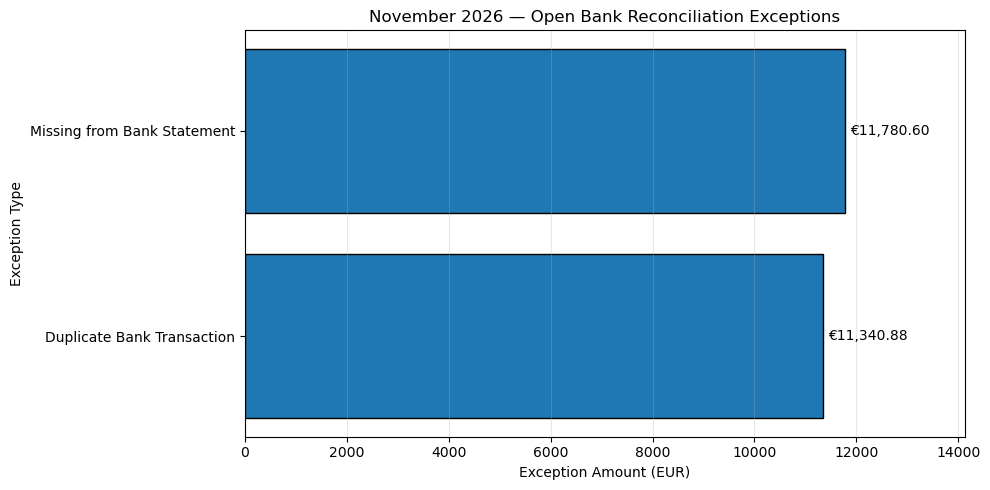

In [39]:
# ==========================================
# IMPROVED EXCEPTION CHART
# ==========================================

import matplotlib.pyplot as plt

exception_chart = exception_register.groupby(
    "exception_type"
)["amount"].sum().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    exception_chart.index,
    exception_chart.values,
    edgecolor="black"
)

# Add euro values to the bars
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 100,
        bar.get_y() + bar.get_height() / 2,
        f"€{value:,.2f}",
        va="center"
    )

ax.set_title(
    "November 2026 — Open Bank Reconciliation Exceptions"
)
ax.set_xlabel("Exception Amount (EUR)")
ax.set_ylabel("Exception Type")
ax.grid(axis="x", alpha=0.3)

ax.set_xlim(0, exception_chart.max() * 1.2)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" /
    "bank_reconciliation_exceptions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
# ==========================================
# AUDIT TRAIL — BANK RECONCILIATION
# ==========================================

audit_trail = pd.DataFrame([
    {
        "audit_id": "AUD001",
        "transaction_id": "TXN00015",
        "finding": "Missing from Bank Statement",
        "initial_amount": 11780.60,
        "action_taken": "Flagged for investigation",
        "current_status": "Open",
        "resolution_amount": 0.00
    },
    {
        "audit_id": "AUD002",
        "transaction_id": "TXN00018",
        "finding": "Duplicate Bank Transaction",
        "initial_amount": 11340.88,
        "action_taken": "Flagged for duplicate verification",
        "current_status": "Open",
        "resolution_amount": 0.00
    },
    {
        "audit_id": "AUD003",
        "transaction_id": "BANKFEE001",
        "finding": "Bank Fee Missing from General Ledger",
        "initial_amount": 45.00,
        "action_taken": "Debit Bank Charges and credit Bank Account",
        "current_status": "Resolved",
        "resolution_amount": 45.00
    }
])

print("NORTHSTAR GLOBAL SERVICES LTD.")
print("BANK RECONCILIATION AUDIT TRAIL")
print("=" * 75)

display(audit_trail)

# Save audit trail
audit_trail.to_csv(
    PROJECT_ROOT / "data" / "processed" /
    "audit_trail.csv",
    index=False
)

print("Audit trail saved successfully.")

NORTHSTAR GLOBAL SERVICES LTD.
BANK RECONCILIATION AUDIT TRAIL


,audit_id,transaction_id,finding,initial_amount,action_taken,current_status,resolution_amount
0,AUD001,TXN00015,Missing from Bank Statement,11780.60,Flagged for investigation,Open,0.0
1,AUD002,TXN00018,Duplicate Bank Transaction,11340.88,Flagged for duplicate verification,Open,0.0
2,AUD003,BANKFEE001,Bank Fee Missing from General Ledger,45.00,Debit Bank Charges and credit Bank Account,Resolved,45.0


Audit trail saved successfully.


In [41]:
# ==========================================
# PROJECT FILE INVENTORY
# ==========================================

for folder in [
    "data/raw",
    "data/processed",
    "notebooks",
    "src",
    "sql",
    "reports",
    "dashboard"
]:
    path = PROJECT_ROOT / folder

    print(f"\n{folder}/")

    if path.exists():
        files = sorted(path.iterdir())

        if files:
            for file in files:
                if file.is_file():
                    print(f"  - {file.name}")
        else:
            print("  (empty)")
    else:
        print("  (folder not found)")


data/raw/
  - accounts_payable.csv
  - accounts_receivable.csv
  - bank_statement.csv
  - budget.csv
  - chart_of_accounts.csv
  - general_ledger.csv

data/processed/
  - audit_trail.csv
  - balance_sheet.csv
  - bank_reconciliation.csv
  - budget_vs_actual.csv
  - exception_register.csv
  - financial_summary.csv
  - month_end_control_summary.csv
  - profit_and_loss.csv

notebooks/
  - 01_project_setup.ipynb
  - 02_generate_financial_data.ipynb.ipynb

src/
  (empty)

sql/
  (empty)

reports/
  - bank_reconciliation_exceptions.png

dashboard/
  (empty)
